# Flood check: drinking-water violations (SDWIS)

**Summary.** Drinking-water violations become more common right after a flood: the share of zip-months with at least one health-based violation rises from 3.7% to 4.2% (CRS 2.8% to 3.4%, non-CRS 4.3% to 4.8%). CRS zip codes start lower but see a similar increase.

New health-based Safe Drinking Water Act violations in the community water systems serving each zip code (EPA SDWIS, mapped to ZCTAs with EPA service-area boundaries). **Before** = months -12 to -2 (non-flood months); **after** = the loss month and the month after. FEMA zip-days 1992-2019 in zips with a mapped system. Function: `check_data_sdwis`.

Violations are counts per zip-month, mostly zero, so the top row shows the share of zip-months with 0, 1, 2, 3+ violations and the bottom row the change in violations per month (after minus before average).

For each FEMA NFIP zip-day (all claims in a zip code on one date of loss), the outcome before the flood is compared with the outcome after it, for all floods, for zip-days whose claims are all in CRS communities (`crs_treat = 1`) and for those with none (`crs_treat = 0`). Mixed zip-days are included in *all floods* only.

**Top:** distribution of the outcome before vs. after. **Bottom:** each zip-day's own change (dashed: no change; solid orange: median). These are raw comparisons, not adjusted for season, region or repeated floods, and zip-days from the same zip or storm are not independent.

**Caveat:** `crs_treat = 0` includes claims whose CRS class is missing in the source (37% of claims), so *non-CRS* partly means *CRS status unknown*. Data preparation is in `bin/data/ai2_dataset.py`; methods in `bin/data/METHODS.md`.

In [1]:
import os, sys
import numpy as np

# pipeline code: bin/data/ai2_dataset.py (data paths: AI2_DATA_DIR, default /Users/chang/data/ai2)
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'bin', 'data')))
import ai2_dataset as A

In [2]:
# --- plotting ---
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import gridspec
mpl.rcParams['text.usetex'] = True
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['axes.linewidth'] = 1.5
mpl.rcParams['axes.xmargin'] = 1
mpl.rcParams['xtick.labelsize'] = 'x-large'
mpl.rcParams['xtick.major.size'] = 5
mpl.rcParams['xtick.major.width'] = 1.5
mpl.rcParams['ytick.labelsize'] = 'x-large'
mpl.rcParams['ytick.major.size'] = 5
mpl.rcParams['ytick.major.width'] = 1.5
mpl.rcParams['legend.frameon'] = False
%matplotlib inline

In [3]:
GROUPS = [('all floods', None), ('CRS', 1.), ('non-CRS', 0.)]


def select(crs, val):
    return np.ones(len(crs), dtype=bool) if val is None else (crs == val)


def summary(before, after, crs, log=True):
    """median before/after and paired change for all floods, CRS and non-CRS"""
    print(f"{'':12s} {'n':>8s} {'median before':>14s} {'median after':>13s} {'median change':>14s} {'mean change':>12s} {'up':>5s} {'down':>5s}")
    for name, val in GROUPS:
        s = select(crs, val)
        b, a = before[s], after[s]
        if log:
            pos = (b > 0) & (a > 0)
            b, a = b[pos], a[pos]
            d = np.log(a / b)
            med, mean = f'{np.expm1(np.median(d)):+.1%}', f'{np.expm1(d.mean()):+.1%}'
        else:
            d = a - b
            med, mean = f'{np.median(d):+.3f}', f'{d.mean():+.4f}'
        print(f"{name:12s} {len(d):8d} {np.median(b):14.3g} {np.median(a):13.3g} {med:>14s} {mean:>12s} "
              f"{(d > 0).mean():5.0%} {(d < 0).mean():5.0%}")


def plot_check(before, after, crs, xlabel, log=True, nbins=40):
    """top: outcome distribution before vs. after a flood loss;
    bottom: each zip-day's own change; columns: all floods, CRS, non-CRS"""
    fig = plt.figure(figsize=(18, 9))
    gs = gridspec.GridSpec(2, 3, hspace=0.35, wspace=0.08)
    for j, (name, val) in enumerate(GROUPS):
        s = select(crs, val)
        b, a = before[s], after[s]
        if log:
            pos = (b > 0) & (a > 0)
            b, a = b[pos], a[pos]

        # distribution before vs. after
        sub = plt.subplot(gs[0, j])
        lo, hi = np.percentile(np.concatenate([b, a]), [0.5, 99.5])
        bins = np.logspace(np.log10(lo), np.log10(hi), nbins+1) if log else np.linspace(lo, hi, nbins+1)
        _ = sub.hist(b, bins=bins, density=True, alpha=0.5, color='C0', label='before')
        _ = sub.hist(a, bins=bins, density=True, alpha=0.5, color='C1', label='after')
        _ = sub.hist(b, bins=bins, density=True, histtype='step', color='C0')
        _ = sub.hist(a, bins=bins, density=True, histtype='step', color='C1')
        if log: sub.set_xscale('log')
        sub.set_xlim(lo, hi)
        sub.set_ylim(0, 1.4 * sub.get_ylim()[1])   # room for the labels
        sub.set_yticks([])
        sub.text(0.04, 0.95, name, transform=sub.transAxes, ha='left', va='top', fontsize=22)
        sub.text(0.04, 0.82, r'$N=%s$' % f'{len(b):,}'.replace(',', '{,}'), transform=sub.transAxes,
                 ha='left', va='top', fontsize=15)
        if j == 0: sub.legend(loc='upper right', fontsize=20, handletextpad=0.2)
        if j == 1: sub.set_xlabel(xlabel, fontsize=22)

        # each zip-day's change
        sub = plt.subplot(gs[1, j])
        d = np.log(a / b) if log else a - b
        lim = np.percentile(np.abs(d), 99) or 1.
        _ = sub.hist(d, bins=60, range=(-lim, lim), alpha=0.5, color='C0')
        _ = sub.hist(d, bins=60, range=(-lim, lim), histtype='step', color='C0')
        sub.axvline(0., color='k', linestyle='--')
        sub.axvline(np.median(d), color='C1', linestyle='-', linewidth=2)
        sub.set_xlim(-lim, lim)
        sub.set_yscale('log')
        sub.set_ylim(0.7, 8 * sub.get_ylim()[1])    # room for the label
        sub.set_yticks([])
        sub.yaxis.set_minor_locator(mpl.ticker.NullLocator())
        chg = (r'median $%+.1f\%%$' % (100 * np.expm1(np.median(d)))) if log else (r'mean $%+.4f$' % d.mean())
        sub.text(0.96, 0.95, chg, transform=sub.transAxes, ha='right', va='top', fontsize=16)
        if j == 1:
            sub.set_xlabel(r'$\ln$(after / before)' if log else 'after $-$ before (per month)', fontsize=22)
    plt.show()

In [4]:
pre, post, crs = A.check_data_sdwis()
summary(pre.mean(0), post.mean(0), crs, log=False)
for name, val in GROUPS:
    s = select(crs, val)
    print(f"{name:12s} zip-months with >=1 violation: before {(pre[:, s] > 0).mean():.2%}  after {(post[:, s] > 0).mean():.2%}")

                    n  median before  median after  median change  mean change    up  down
all floods     225652              0             0         +0.000      +0.0079    7%   16%
CRS             88796              0             0         +0.000      +0.0069    6%   14%
non-CRS        127087              0             0         +0.000      +0.0086    8%   17%
all floods   zip-months with >=1 violation: before 3.67%  after 4.24%
CRS          zip-months with >=1 violation: before 2.79%  after 3.38%
non-CRS      zip-months with >=1 violation: before 4.28%  after 4.81%


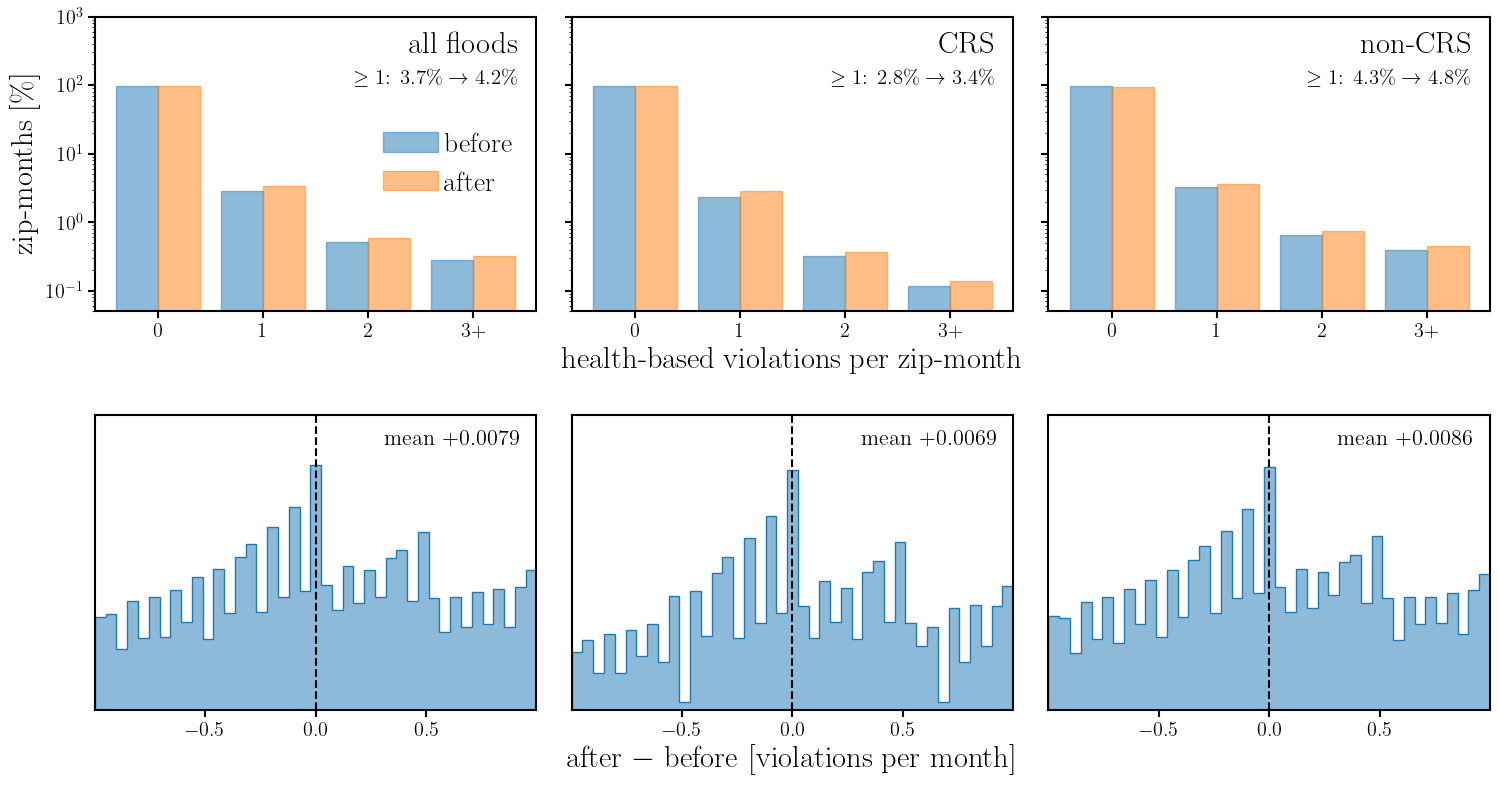

In [5]:
fig = plt.figure(figsize=(18, 9))
gs = gridspec.GridSpec(2, 3, hspace=0.35, wspace=0.08)
cats = ['0', '1', '2', '3+']
share = lambda x: np.array([np.mean(x == 0), np.mean(x == 1), np.mean(x == 2), np.mean(x >= 3)])
for j, (name, val) in enumerate(GROUPS):
    s = select(crs, val)
    b, a = pre[:, s].ravel(), post[:, s].ravel()

    # share of zip-months with 0/1/2/3+ violations
    sub = plt.subplot(gs[0, j])
    xs = np.arange(4)
    sub.bar(xs - 0.2, 100 * share(b), 0.4, alpha=0.5, color='C0', edgecolor='C0', label='before')
    sub.bar(xs + 0.2, 100 * share(a), 0.4, alpha=0.5, color='C1', edgecolor='C1', label='after')
    sub.set_yscale('log')
    sub.set_ylim(0.05, 1000)                    # same range in every panel
    sub.set_xlim(-0.6, 3.6)
    sub.set_xticks(xs)
    sub.set_xticklabels(cats)
    if j > 0: sub.set_yticklabels([])
    sub.text(0.96, 0.95, name, transform=sub.transAxes, ha='right', va='top', fontsize=22)
    sub.text(0.96, 0.82, r'$\geq 1$: $%.1f\%% \rightarrow %.1f\%%$' % (100*(b > 0).mean(), 100*(a > 0).mean()),
             transform=sub.transAxes, ha='right', va='top', fontsize=15)
    if j == 0:
        sub.set_ylabel(r'zip-months [\%]', fontsize=22)
        sub.legend(loc='center right', fontsize=20, handletextpad=0.2)
    if j == 1: sub.set_xlabel('health-based violations per zip-month', fontsize=22)

    # change in violations per month
    sub = plt.subplot(gs[1, j])
    d = post[:, s].mean(0) - pre[:, s].mean(0)
    _ = sub.hist(d, bins=41, range=(-1, 1), alpha=0.5, color='C0')
    _ = sub.hist(d, bins=41, range=(-1, 1), histtype='step', color='C0')
    sub.axvline(0., color='k', linestyle='--')
    sub.set_xlim(-1, 1)
    sub.set_xticks([-0.5, 0., 0.5])
    sub.set_yscale('log')
    sub.set_ylim(0.7, 8 * sub.get_ylim()[1])
    sub.set_yticks([])
    sub.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    sub.text(0.96, 0.95, r'mean $%+.4f$' % d.mean(), transform=sub.transAxes, ha='right', va='top', fontsize=16)
    if j == 1: sub.set_xlabel(r'after $-$ before [violations per month]', fontsize=22)
plt.show()